# 9. Class-Specific Error Analysis: Why Is **Enrolled** Hard to Predict?

This notebook follows the same project split, preprocessing pipeline, class balancing, and model definitions used in the existing model-comparison workflow.

### Goal

The main question is not simply *"What is Enrolled recall?"* Instead, we ask:

**Is Enrolled an ambiguous/intermediate class whose students overlap with both Dropout and Graduate profiles?**

We examine Logistic Regression, Random Forest, and XGBoost on the **same holdout rows** and focus on actual Enrolled students who are:

1. correctly predicted as **Enrolled**
2. incorrectly predicted as **Dropout**
3. incorrectly predicted as **Graduate**

We then compare their academic progress, financial status, and model confidence.

**Default:** `Full Data`, matching the direct per-class comparison in the model-comparison notebook.  
To make the analysis strictly early-warning oriented, change `ANALYSIS_FEATURE_SET` to `"After Semester 1"`.

**Keep in mind throughout:** "Enrolled" is the student's status when the data was collected, not a final outcome. Some Enrolled students will later graduate and some will drop out, so this class is mixed by construction. That alone predicts some of the overlap found below.


In [1]:
import sys
from pathlib import Path

cwd = Path.cwd()
project_root = cwd if (cwd / "requirements.txt").exists() else cwd.parent
sys.path.append(str(project_root))


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import confusion_matrix

from src.evaluate import (
    evaluate_feature_set,
    evaluate_xgboost_feature_set,
)
from src.models import (
    get_logistic_regression,
    get_random_forest,
)
from src.preprocessing import (
    get_feature_availability_sets,
    load_data,
)

sns.set_theme(style="whitegrid")

CLASSES = ["Dropout", "Enrolled", "Graduate"]
ANALYSIS_FEATURE_SET = "Full Data"   # change to "After Semester 1" if desired

df = load_data()
feature_sets = get_feature_availability_sets(df)
feature_cols = feature_sets[ANALYSIS_FEATURE_SET]

print("Analysis feature set:", ANALYSIS_FEATURE_SET)
print("Number of predictors:", len(feature_cols))
print("Dataset shape:", df.shape)


Analysis feature set: Full Data
Number of predictors: 36
Dataset shape: (4424, 37)


## 9.1 Refit all three models on the exact project holdout split

The shared evaluation utilities use the same stratified 80/20 split and `random_state=42`.  
Logistic Regression scales numeric variables; Random Forest and XGBoost do not.  
Class balancing is handled exactly as in the project code.


In [3]:
# Logistic Regression
_, pipe_lr, X_test_lr, y_test_lr, y_pred_lr = evaluate_feature_set(
    df=df,
    feature_cols=feature_cols,
    feature_set_name=ANALYSIS_FEATURE_SET,
    model=get_logistic_regression(random_state=42),
    scale_numeric=True,
    return_split=True,
)

# Random Forest
_, pipe_rf, X_test_rf, y_test_rf, y_pred_rf = evaluate_feature_set(
    df=df,
    feature_cols=feature_cols,
    feature_set_name=ANALYSIS_FEATURE_SET,
    model=get_random_forest(random_state=42),
    scale_numeric=False,
    return_split=True,
)

# XGBoost
_, pipe_xgb, X_test_xgb, y_test_xgb, y_pred_xgb = evaluate_xgboost_feature_set(
    df=df,
    feature_cols=feature_cols,
    feature_set_name=ANALYSIS_FEATURE_SET,
    return_split=True,
)

# Convert all labels to aligned Series indexed by the original row index.
y_test = pd.Series(np.asarray(y_test_lr), index=X_test_lr.index, name="Actual")
predictions = {
    "Logistic Regression": pd.Series(np.asarray(y_pred_lr), index=X_test_lr.index),
    "Random Forest": pd.Series(np.asarray(y_pred_rf), index=X_test_lr.index),
    "XGBoost": pd.Series(np.asarray(y_pred_xgb), index=X_test_lr.index),
}


# Verify matching holdout rows and true labels.
assert X_test_lr.index.equals(X_test_rf.index)
assert X_test_lr.index.equals(X_test_xgb.index)

assert np.array_equal(
    np.asarray(y_test_lr), np.asarray(y_test_rf)
)
assert np.array_equal(
    np.asarray(y_test_lr), np.asarray(y_test_xgb)
)


print("Holdout size:", len(y_test))
print(y_test.value_counts())


Holdout size: 885
Actual
Graduate    442
Dropout     284
Enrolled    159
Name: count, dtype: int64


## 9.2 Confusion matrices

First, examine the full error structure. The row-normalized matrices answer:

*Given a student's true outcome, where does the model send that student?*

For the Enrolled row, the two off-diagonal cells are especially important:
- **Enrolled → Dropout**
- **Enrolled → Graduate**


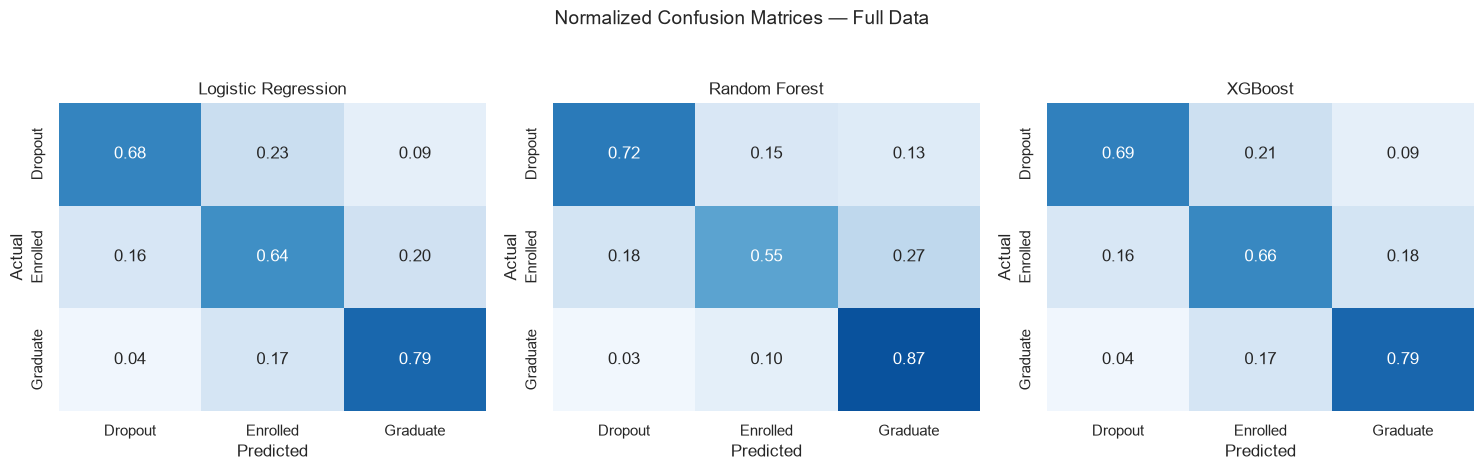

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, (model_name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=CLASSES,
        normalize="true"
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt=".2f",
        cmap="Blues",
        vmin=0,
        vmax=1,
        xticklabels=CLASSES,
        yticklabels=CLASSES,
        ax=ax,
        cbar=False,
    )
    ax.set_title(model_name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

fig.suptitle(
    f"Normalized Confusion Matrices — {ANALYSIS_FEATURE_SET}",
    y=1.04,
    fontsize=14
)
plt.tight_layout()
plt.show()


## 9.3 Where do actual Enrolled students go?

This table makes the Enrolled errors explicit instead of summarizing them only through recall.


In [5]:
enrolled_error_rows = []

for model_name, y_pred in predictions.items():
    actual_enrolled = y_test.eq("Enrolled")
    pred_counts = y_pred.loc[actual_enrolled].value_counts().reindex(CLASSES, fill_value=0)
    n_enrolled = actual_enrolled.sum()

    for predicted_class in CLASSES:
        enrolled_error_rows.append({
            "Model": model_name,
            "Predicted as": predicted_class,
            "Count": int(pred_counts[predicted_class]),
            "Percent of actual Enrolled": pred_counts[predicted_class] / n_enrolled
        })

enrolled_destinations = pd.DataFrame(enrolled_error_rows)

display(
    enrolled_destinations.assign(
        **{"Percent of actual Enrolled":
           enrolled_destinations["Percent of actual Enrolled"].map(lambda x: f"{100*x:.1f}%")}
    )
)


,Model,Predicted as,Count,Percent of actual Enrolled
0,Logistic Regression,Dropout,26,16.4%
1,Logistic Regression,Enrolled,101,63.5%
2,Logistic Regression,Graduate,32,20.1%
3,Random Forest,Dropout,29,18.2%
4,Random Forest,Enrolled,87,54.7%
5,Random Forest,Graduate,43,27.0%
6,XGBoost,Dropout,25,15.7%
7,XGBoost,Enrolled,105,66.0%
8,XGBoost,Graduate,29,18.2%


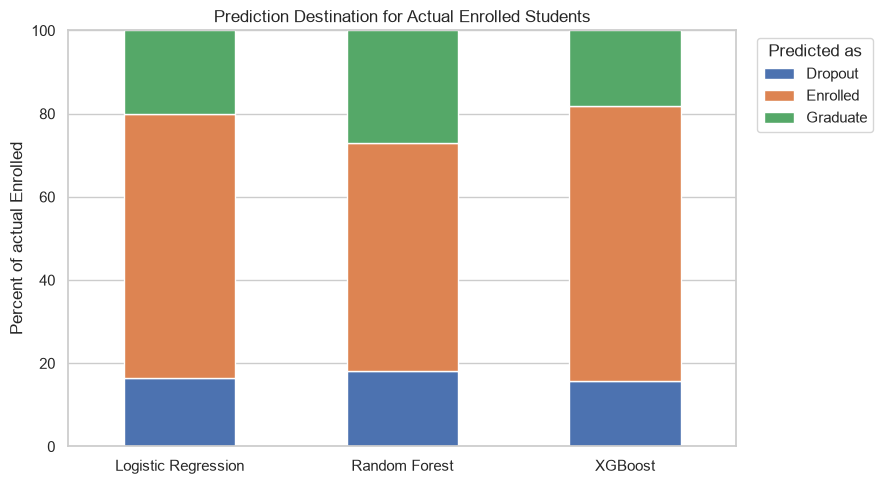

In [6]:
plot_df = enrolled_destinations.copy()
plot_df["Percent"] = 100 * plot_df["Percent of actual Enrolled"]

pivot = (
    plot_df.pivot(index="Model", columns="Predicted as", values="Percent")
    .reindex(columns=CLASSES)
)

ax = pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

ax.set_title("Prediction Destination for Actual Enrolled Students")
ax.set_xlabel("")
ax.set_ylabel("Percent of actual Enrolled")
ax.set_ylim(0, 100)
ax.legend(title="Predicted as", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


All three models struggle to distinguish Enrolled students from the two terminal outcomes. Logistic Regression correctly identifies 63.5% of actual Enrolled students, compared with 54.7% for Random Forest and 66.0% for XGBoost. The remaining Enrolled students are misclassified in both directions, although confusion with Graduate is more common across all three models. This suggests that Enrolled students may share characteristics with both Dropout and Graduate students rather than forming a clearly separated group.


## 9.4 Build actual-Enrolled error groups

We keep the raw holdout values so the summaries remain easy to explain.  
The derived approval rate is used **only for interpretation**; it is not added to the fitted model.


In [7]:
def safe_ratio(num, den):
    num = pd.to_numeric(num, errors="coerce")
    den = pd.to_numeric(den, errors="coerce")
    return np.where(den > 0, num / den, np.nan)

def make_enrolled_error_frame(model_name, y_pred):
    mask = y_test.eq("Enrolled")
    out = X_test_lr.loc[mask].copy()
    out["Actual"] = "Enrolled"
    out["Predicted"] = y_pred.loc[mask].values
    out["Model"] = model_name

    out["Enrolled error group"] = out["Predicted"].map({
        "Enrolled": "Correct: Enrolled",
        "Dropout": "Mistaken for Dropout",
        "Graduate": "Mistaken for Graduate",
    })

    out["Sem1 approval rate"] = safe_ratio(
        out["Curricular units 1st sem (approved)"],
        out["Curricular units 1st sem (enrolled)"]
    )

    if "Curricular units 2nd sem (approved)" in out.columns:
        out["Sem2 approval rate"] = safe_ratio(
            out["Curricular units 2nd sem (approved)"],
            out["Curricular units 2nd sem (enrolled)"]
        )

    return out

enrolled_groups = pd.concat(
    [make_enrolled_error_frame(name, pred) for name, pred in predictions.items()],
    ignore_index=True
)

display(
    enrolled_groups[["Model", "Enrolled error group"]]
    .value_counts()
    .rename("n")
    .reset_index()
)


,Model,Enrolled error group,n
0,XGBoost,Correct: Enrolled,105
1,Logistic Regression,Correct: Enrolled,101
2,Random Forest,Correct: Enrolled,87
3,Random Forest,Mistaken for Graduate,43
4,Logistic Regression,Mistaken for Graduate,32
5,Random Forest,Mistaken for Dropout,29
6,XGBoost,Mistaken for Graduate,29
7,Logistic Regression,Mistaken for Dropout,26
8,XGBoost,Mistaken for Dropout,25


## 9.5 Compare the three Enrolled subgroups

The variables below were chosen because they are interpretable and tied to academic progress or financial standing:

- Semester-1 grade
- Semester-1 approved, enrolled, and evaluated units
- Semester-1 approval rate
- Units without evaluations
- Tuition-fee status and debtor status
- Scholarship status
- Age at enrollment

When Full Data is used, Semester-2 grade/approved units are also included as descriptive context.

For binary variables such as tuition status, the mean is the **proportion equal to 1**.


In [8]:
focus_features = [
    "Curricular units 1st sem (grade)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)",
    "Sem1 approval rate",
    "Curricular units 1st sem (without evaluations)",
    "Tuition fees up to date",
    "Debtor",
    "Scholarship holder",
    "Age at enrollment",
]

# Add Semester-2 descriptors only when they are in the chosen model feature set.
if "Curricular units 2nd sem (grade)" in feature_cols:
    focus_features += [
        "Curricular units 2nd sem (grade)",
        "Curricular units 2nd sem (approved)",
        "Sem2 approval rate",
    ]

group_order = [
    "Mistaken for Dropout",
    "Correct: Enrolled",
    "Mistaken for Graduate",
]

profile_summary = (
    enrolled_groups
    .groupby(["Model", "Enrolled error group"])[focus_features]
    .mean()
    .reindex(
        pd.MultiIndex.from_product(
            [list(predictions.keys()), group_order],
            names=["Model", "Enrolled error group"]
        )
    )
)

# Add group sample sizes beside the profile table.
group_n = (
    enrolled_groups
    .groupby(["Model", "Enrolled error group"])
    .size()
    .rename("n")
)

profile_with_n = profile_summary.join(group_n)
cols = ["n"] + focus_features
display(profile_with_n[cols].round(3))

n  \
Model               Enrolled error group         
Logistic Regression Mistaken for Dropout    26   
                    Correct: Enrolled      101   
                    Mistaken for Graduate   32   
Random Forest       Mistaken for Dropout    29   
                    Correct: Enrolled       87   
                    Mistaken for Graduate   43   
XGBoost             Mistaken for Dropout    25   
                    Correct: Enrolled      105   
                    Mistaken for Graduate   29   

                                           Curricular units 1st sem (grade)  \
Model               Enrolled error group                                      
Logistic Regression Mistaken for Dropout                             10.303   
                    Correct: Enrolled                                11.059   
                    Mistaken for Graduate                            11.776   
Random Forest       Mistaken for Dropout                              9.446   
                    Correct: Enrolled                                11.371   
                    Mistaken for Graduate                            11.592   
XGBoost             Mistaken for Dropout                              8.832   
                    Correct: Enrolled                                11.565   
                    Mistaken for Graduate                            11.261   

                                           Curricular units 1st sem (approved)  \
Model               Enrolled error group                                         
Logistic Regression Mistaken for Dropout                                 3.231   
                    Correct: Enrolled                                    3.881   
                    Mistaken for Graduate                                5.719   
Random Forest       Mistaken for Dropout                                 2.931   
                    Correct: Enrolled                                    4.000   
                    Mistaken for Graduate                                5.256   
XGBoost             Mistaken for Dropout                                 2.720   
                    Correct: Enrolled                                    4.210   
                    Mistaken for Graduate                                5.138   

                                           Curricular units 1st sem (enrolled)  \
Model               Enrolled error group                                         
Logistic Regression Mistaken for Dropout                                 5.538   
                    Correct: Enrolled                                    5.634   
                    Mistaken for Graduate                                6.281   
Random Forest       Mistaken for Dropout                                 5.414   
                    Correct: Enrolled                                    5.736   
                    Mistaken for Graduate                                6.000   
XGBoost             Mistaken for Dropout                                 5.480   
                    Correct: Enrolled                                    5.781   
                    Mistaken for Graduate                                5.862   

                                           Curricular units 1st sem (evaluations)  \
Model               Enrolled error group                                            
Logistic Regression Mistaken for Dropout                                    8.538   
                    Correct: Enrolled                                       9.218   
                    Mistaken for Graduate                                   8.219   
Random Forest       Mistaken for Dropout                                    8.517   
                    Correct: Enrolled                                       9.598   
                    Mistaken for Graduate                                   7.767   
XGBoost             Mistaken for Dropout                                    8.480   
                    Correct: Enrolled                

Financial variables also differ across the three groups. Enrolled students predicted as Dropout are generally less likely to have their tuition fees up to date and more likely to have debtor status than the other Enrolled groups. For example, under XGBoost, 80.0% of Enrolled students predicted as Dropout have tuition fees up to date, compared with 97.1% of correctly predicted Enrolled students and 100% of those predicted as Graduate. These differences suggest that financial standing, along with academic progress, may contribute to the overlap between the Enrolled and Dropout profiles.

In [9]:
# Compact summary table
summary_features = [
    "Curricular units 1st sem (grade)",
    "Curricular units 1st sem (approved)",
    "Sem1 approval rate",
    "Tuition fees up to date",
]

round2_summary = profile_with_n[
    ["n"] + summary_features
].copy()

round2_summary = round2_summary.rename(columns={
    "Curricular units 1st sem (grade)": "Sem1 Grade",
    "Curricular units 1st sem (approved)": "Sem1 Approved",
    "Sem1 approval rate": "Approval Rate",
    "Tuition fees up to date": "Tuition Current",
})

round2_summary["Approval Rate"] *= 100
round2_summary["Tuition Current"] *= 100

display(round2_summary.round(1))


n  Sem1 Grade  Sem1 Approved  \
Model               Enrolled error group                                    
Logistic Regression Mistaken for Dropout    26        10.3            3.2   
                    Correct: Enrolled      101        11.1            3.9   
                    Mistaken for Graduate   32        11.8            5.7   
Random Forest       Mistaken for Dropout    29         9.4            2.9   
                    Correct: Enrolled       87        11.4            4.0   
                    Mistaken for Graduate   43        11.6            5.3   
XGBoost             Mistaken for Dropout    25         8.8            2.7   
                    Correct: Enrolled      105        11.6            4.2   
                    Mistaken for Graduate   29        11.3            5.1   

                                           Approval Rate  Tuition Current  
Model               Enrolled error group                                   
Logistic Regression Mistaken for Dropout            59.3             80.8  
                    Correct: Enrolled               68.6             97.0  
                    Mistaken for Graduate           91.2            100.0  
Random Forest       Mistaken for Dropout            55.5             86.2  
                    Correct: Enrolled               69.3             97.7  
                    Mistaken for Graduate           87.6             95.3  
XGBoost             Mistaken for Dropout            49.5             80.0  
                    Correct: Enrolled               72.7             97.1  
                    Mistaken for Graduate           86.7            100.0

## 9.6 Visual checks of the "intermediate" hypothesis

Semester-1 grade and approval rate are especially useful because they summarize academic performance in a form that is easy to explain.

If Enrolled students mistaken for Dropout cluster lower, and those mistaken for Graduate cluster higher, that is direct evidence that the model is splitting the Enrolled class along a performance continuum.


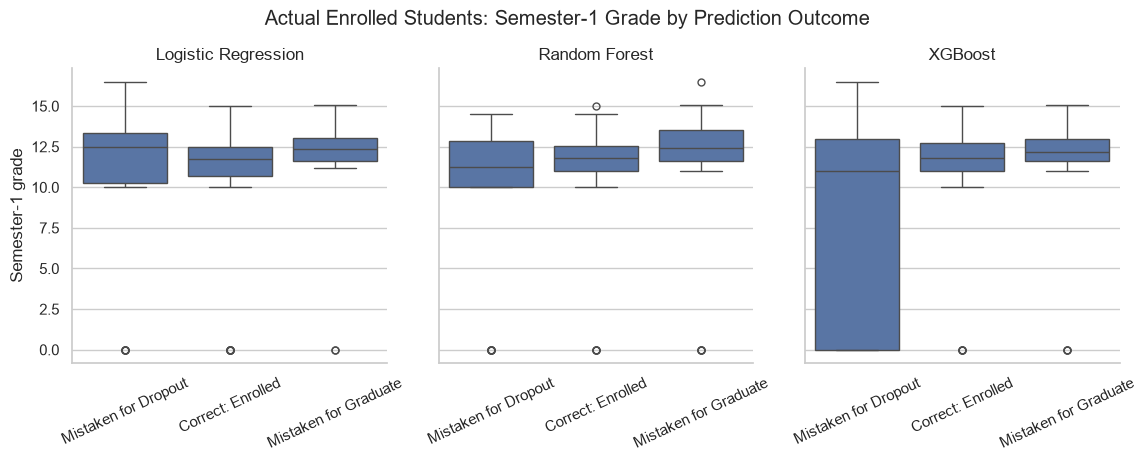

In [10]:
g = sns.catplot(
    data=enrolled_groups,
    x="Enrolled error group",
    y="Curricular units 1st sem (grade)",
    col="Model",
    order=group_order,
    kind="box",
    height=4,
    aspect=0.95,
    sharey=True,
)
g.set_axis_labels("", "Semester-1 grade")
g.set_titles("{col_name}")
for ax in g.axes.flat:
    ax.tick_params(axis="x", rotation=25)
g.fig.suptitle(
    "Actual Enrolled Students: Semester-1 Grade by Prediction Outcome",
    y=1.05
)
plt.show()


Semester-1 grades also help distinguish the Enrolled error groups. Across all three models, Enrolled students predicted as Dropout have lower average grades than correctly identified Enrolled students or those predicted as Graduate. However, the ordering between the latter two groups is less consistent, particularly for XGBoost. This suggests that grades alone do not fully explain Enrolled misclassification, and measures of academic completion, such as approved units and approval rates, may provide a clearer explanation.

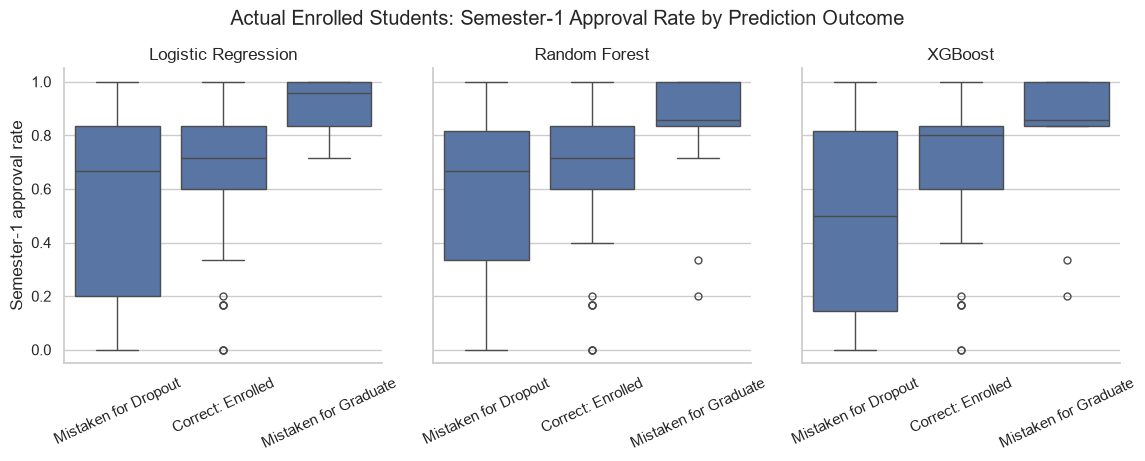

In [11]:
g = sns.catplot(
    data=enrolled_groups,
    x="Enrolled error group",
    y="Sem1 approval rate",
    col="Model",
    order=group_order,
    kind="box",
    height=4,
    aspect=0.95,
    sharey=True,
)
g.set_axis_labels("", "Semester-1 approval rate")
g.set_titles("{col_name}")
for ax in g.axes.flat:
    ax.tick_params(axis="x", rotation=25)
g.fig.suptitle(
    "Actual Enrolled Students: Semester-1 Approval Rate by Prediction Outcome",
    y=1.05
)
plt.show()


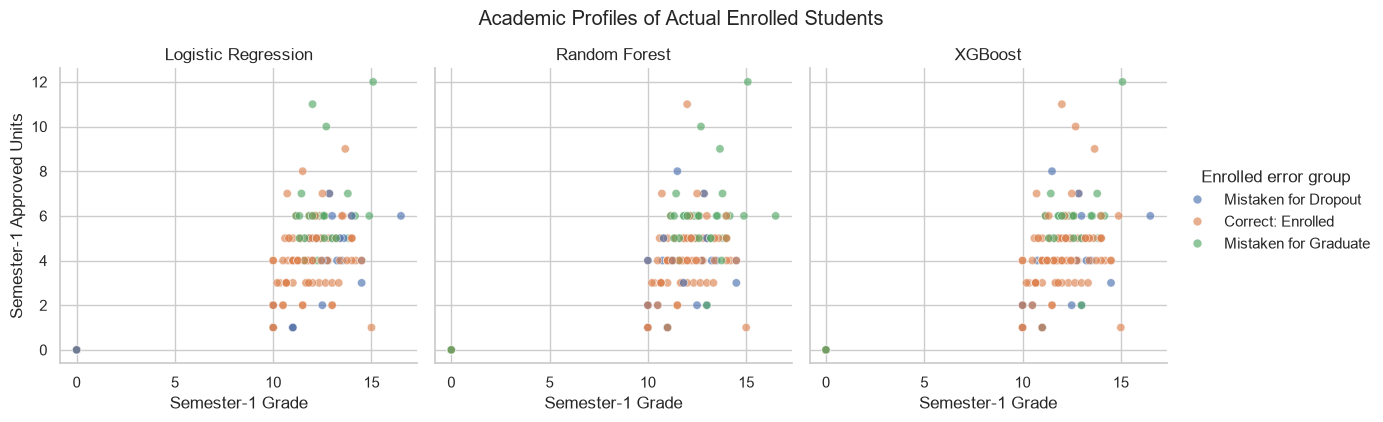

In [12]:

g = sns.relplot(
    data=enrolled_groups,
    x="Curricular units 1st sem (grade)",
    y="Curricular units 1st sem (approved)",
    hue="Enrolled error group",
    hue_order=group_order,
    col="Model",
    kind="scatter",
    alpha=0.65,
    height=4,
    aspect=1,
)

g.set_axis_labels(
    "Semester-1 Grade",
    "Semester-1 Approved Units"
)
g.set_titles("{col_name}")

g.fig.suptitle(
    "Academic Profiles of Actual Enrolled Students",
    y=1.05
)

plt.show()


Academic progress shows a consistent pattern across the three Enrolled error groups. Students incorrectly predicted as Dropout have the lowest Semester-1 approval rates, while those predicted as Graduate have the highest. Correctly predicted Enrolled students fall between these groups. For example, under XGBoost, the average approval rates are 49.5%, 72.7%, and 86.7%, respectively. Similar patterns appear in the number of approved curricular units. These results support the hypothesis that the Enrolled class contains students with a range of academic profiles, some resembling Dropout students and others resembling Graduates.

## 9.7 Compare error groups with true Dropout and Graduate reference profiles

This is a stronger check of the hypothesis.

For each model, compare:
- **true Dropout** students in the holdout set,
- actual Enrolled students mistaken for Dropout,
- correctly identified Enrolled students,
- actual Enrolled students mistaken for Graduate,
- **true Graduate** students in the holdout set.

If the two Enrolled error groups move toward their corresponding endpoint class, the errors are substantively meaningful rather than random.


In [13]:
reference_features = [
    "Curricular units 1st sem (grade)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)",
    "Tuition fees up to date",
    "Debtor",
]

reference_rows = []

for model_name, y_pred in predictions.items():
    tmp = X_test_lr.copy()
    tmp["Actual"] = y_test
    tmp["Predicted"] = y_pred

    tmp["Profile group"] = np.select(
        [
            tmp["Actual"].eq("Dropout"),
            tmp["Actual"].eq("Enrolled") & tmp["Predicted"].eq("Dropout"),
            tmp["Actual"].eq("Enrolled") & tmp["Predicted"].eq("Enrolled"),
            tmp["Actual"].eq("Enrolled") & tmp["Predicted"].eq("Graduate"),
            tmp["Actual"].eq("Graduate"),
        ],
        [
            "Actual Dropout",
            "Enrolled → Dropout",
            "Correct Enrolled",
            "Enrolled → Graduate",
            "Actual Graduate",
        ],
        default="Other"
    )

    keep = tmp["Profile group"].ne("Other")
    summary = (
        tmp.loc[keep]
        .groupby("Profile group")[reference_features]
        .mean()
        .assign(Model=model_name)
        .reset_index()
    )
    reference_rows.append(summary)

reference_summary = pd.concat(reference_rows, ignore_index=True)

reference_order = [
    "Actual Dropout",
    "Enrolled → Dropout",
    "Correct Enrolled",
    "Enrolled → Graduate",
    "Actual Graduate",
]

for model_name in predictions:
    print("\n", model_name)
    display(
        reference_summary.loc[reference_summary["Model"].eq(model_name)]
        .set_index("Profile group")
        .reindex(reference_order)[reference_features]
        .round(3)
    )



 Logistic Regression


,Curricular units 1st sem (grade),Curricular units 1st sem (approved),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Tuition fees up to date,Debtor
Profile group,,,,,,
Actual Dropout,7.440,2.496,5.768,7.743,0.673,0.222
Enrolled → Dropout,10.303,3.231,5.538,8.538,0.808,0.231
Correct Enrolled,11.059,3.881,5.634,9.218,0.970,0.109
Enrolled → Graduate,11.776,5.719,6.281,8.219,1.000,0.125
Actual Graduate,12.683,6.369,6.824,8.500,0.982,0.068



 Random Forest


,Curricular units 1st sem (grade),Curricular units 1st sem (approved),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Tuition fees up to date,Debtor
Profile group,,,,,,
Actual Dropout,7.440,2.496,5.768,7.743,0.673,0.222
Enrolled → Dropout,9.446,2.931,5.414,8.517,0.862,0.207
Correct Enrolled,11.371,4.000,5.736,9.598,0.977,0.138
Enrolled → Graduate,11.592,5.256,6.000,7.767,0.953,0.070
Actual Graduate,12.683,6.369,6.824,8.500,0.982,0.068



 XGBoost


,Curricular units 1st sem (grade),Curricular units 1st sem (approved),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Tuition fees up to date,Debtor
Profile group,,,,,,
Actual Dropout,7.440,2.496,5.768,7.743,0.673,0.222
Enrolled → Dropout,8.832,2.720,5.480,8.480,0.800,0.200
Correct Enrolled,11.565,4.210,5.781,9.352,0.971,0.152
Enrolled → Graduate,11.261,5.138,5.862,7.655,1.000,0.000
Actual Graduate,12.683,6.369,6.824,8.500,0.982,0.068


Comparing the Enrolled subgroups with actual Dropout and Graduate students provides further evidence of overlapping academic profiles. For example, Logistic Regression shows a gradual increase in average Semester-1 approved units from actual Dropout students (2.50) to Enrolled students predicted as Dropout (3.23), correctly predicted Enrolled students (3.88), Enrolled students predicted as Graduate (5.72), and actual Graduates (6.37). Similar patterns appear across the other models. This suggests that students classified as Enrolled do not form a completely distinct academic group but instead occupy different positions along a continuum of academic progress.

## 9.8 Model confidence and predicted probabilities

A wrong prediction can mean two different things:

1. the model is **confidently wrong**, suggesting the student's observed profile strongly resembles another outcome; or
2. the model is **uncertain**, suggesting genuine class overlap near a decision boundary.

For each actual Enrolled student, we record:
- probability assigned to Enrolled,
- maximum predicted probability,
- margin between the largest and second-largest probabilities.

A **small margin** means the model saw the case as ambiguous.

**Caution:** these models were trained with class balancing, so their probabilities are not calibrated (they don't match real-world frequencies), and each model's probabilities are on its own scale (Random Forest's are naturally less extreme). Compare confidence **within** a model across the three groups, not **between** models.


In [14]:
def probability_frame(pipe, X_test, model_name, xgb=False):
    prob = pipe.predict_proba(X_test)

    if xgb:
        # evaluate_xgboost_feature_set encodes Dropout/Enrolled/Graduate as 0/1/2.
        prob_cols = CLASSES
    else:
        # sklearn classifiers store the probability-column order in classes_.
        prob_cols = list(pipe.named_steps["model"].classes_)

    prob_df = pd.DataFrame(
        prob,
        index=X_test.index,
        columns=[f"P({c})" for c in prob_cols]
    )

    # Put columns in a consistent order.
    prob_df = prob_df[[f"P({c})" for c in CLASSES]]
    prob_df["Model"] = model_name
    return prob_df

prob_frames = [
    probability_frame(pipe_lr, X_test_lr, "Logistic Regression"),
    probability_frame(pipe_rf, X_test_rf, "Random Forest"),
    probability_frame(pipe_xgb, X_test_xgb, "XGBoost", xgb=True),
]

confidence_rows = []

for prob_df in prob_frames:
    model_name = prob_df["Model"].iloc[0]
    p = prob_df[[f"P({c})" for c in CLASSES]]

    tmp = p.copy()
    tmp["Model"] = model_name
    tmp["Actual"] = y_test
    tmp["Predicted"] = predictions[model_name]

    sorted_prob = np.sort(p.to_numpy(), axis=1)
    tmp["Max probability"] = sorted_prob[:, -1]
    tmp["Top-two margin"] = sorted_prob[:, -1] - sorted_prob[:, -2]
    tmp["P(Enrolled)"] = p["P(Enrolled)"]

    tmp = tmp.loc[tmp["Actual"].eq("Enrolled")].copy()
    tmp["Enrolled error group"] = tmp["Predicted"].map({
        "Enrolled": "Correct: Enrolled",
        "Dropout": "Mistaken for Dropout",
        "Graduate": "Mistaken for Graduate",
    })
    confidence_rows.append(tmp.reset_index(names="row_id"))

enrolled_confidence = pd.concat(confidence_rows, ignore_index=True)

confidence_summary = (
    enrolled_confidence
    .groupby(["Model", "Enrolled error group"])[
        ["P(Enrolled)", "Max probability", "Top-two margin"]
    ]
    .mean()
)

display(confidence_summary.round(3))


P(Enrolled)  Max probability  \
Model               Enrolled error group                                  
Logistic Regression Correct: Enrolled            0.664            0.664   
                    Mistaken for Dropout         0.282            0.687   
                    Mistaken for Graduate        0.259            0.654   
Random Forest       Correct: Enrolled            0.512            0.512   
                    Mistaken for Dropout         0.275            0.585   
                    Mistaken for Graduate        0.274            0.575   
XGBoost             Correct: Enrolled            0.632            0.632   
                    Mistaken for Dropout         0.269            0.689   
                    Mistaken for Graduate        0.217            0.675   

                                           Top-two margin  
Model               Enrolled error group                   
Logistic Regression Correct: Enrolled               0.409  
                    Mistaken for Dropout            0.403  
                    Mistaken for Graduate           0.381  
Random Forest       Correct: Enrolled               0.196  
                    Mistaken for Dropout            0.293  
                    Mistaken for Graduate           0.291  
XGBoost             Correct: Enrolled               0.364  
                    Mistaken for Dropout            0.420  
                    Mistaken for Graduate           0.437

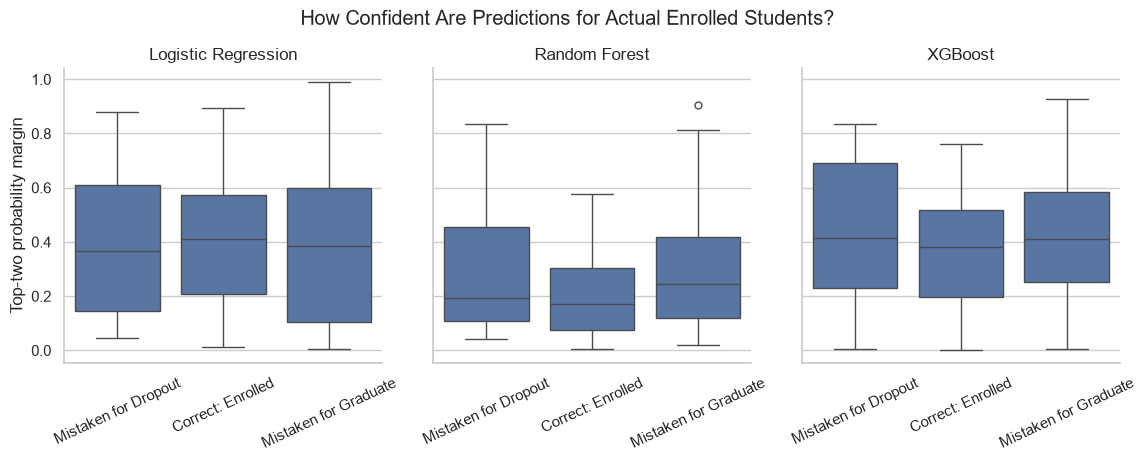

In [15]:
g = sns.catplot(
    data=enrolled_confidence,
    x="Enrolled error group",
    y="Top-two margin",
    col="Model",
    order=group_order,
    kind="box",
    height=4,
    aspect=0.95,
)
g.set_axis_labels("", "Top-two probability margin")
g.set_titles("{col_name}")
for ax in g.axes.flat:
    ax.tick_params(axis="x", rotation=25)
g.fig.suptitle(
    "How Confident Are Predictions for Actual Enrolled Students?",
    y=1.05
)
plt.show()


The predicted probabilities suggest that Enrolled misclassification is not explained entirely by low model confidence. Although Random Forest generally produces smaller top-two probability margins, XGBoost has larger average margins for misclassified Enrolled students than for correctly predicted ones. This suggests that some actual Enrolled students have feature profiles that the models associate relatively strongly with Dropout or Graduate. Therefore, difficulty identifying Enrolled may reflect overlap in observed student characteristics rather than only uncertainty near a decision boundary.

## 9.9  Does the Enrolled confusion change as more information becomes available?

This compact table repeats only the Enrolled destination calculation at:
- Day 1
- After Semester 1
- Full Data

It can show whether ambiguity is mostly an early-information problem or persists even after academic performance becomes available.


In [16]:
stage_rows = []

for stage_name, cols in feature_sets.items():
    # Logistic Regression
    _, _, _, y_lr_stage, pred_lr_stage = evaluate_feature_set(
        df, cols, stage_name,
        get_logistic_regression(random_state=42),
        scale_numeric=True,
        return_split=True
    )

    # Random Forest
    _, _, _, y_rf_stage, pred_rf_stage = evaluate_feature_set(
        df, cols, stage_name,
        get_random_forest(random_state=42),
        scale_numeric=False,
        return_split=True
    )

    # XGBoost
    _, _, _, y_xgb_stage, pred_xgb_stage = evaluate_xgboost_feature_set(
        df=df,
        feature_cols=cols,
        feature_set_name=stage_name,
        return_split=True
    )

    stage_preds = {
        "Logistic Regression": (np.asarray(y_lr_stage), np.asarray(pred_lr_stage)),
        "Random Forest": (np.asarray(y_rf_stage), np.asarray(pred_rf_stage)),
        "XGBoost": (np.asarray(y_xgb_stage), np.asarray(pred_xgb_stage)),
    }

    for model_name, (yt, yp) in stage_preds.items():
        mask = yt == "Enrolled"
        counts = pd.Series(yp[mask]).value_counts().reindex(CLASSES, fill_value=0)
        n = mask.sum()

        stage_rows.append({
            "Feature Set": stage_name,
            "Model": model_name,
            "Enrolled → Dropout": counts["Dropout"] / n,
            "Correct Enrolled": counts["Enrolled"] / n,
            "Enrolled → Graduate": counts["Graduate"] / n,
        })

stage_enrolled_errors = pd.DataFrame(stage_rows)
display(stage_enrolled_errors.round(3))


,Feature Set,Model,Enrolled → Dropout,Correct Enrolled,Enrolled → Graduate
0,Day 1,Logistic Regression,0.126,0.522,0.352
1,Day 1,Random Forest,0.296,0.258,0.447
2,Day 1,XGBoost,0.157,0.497,0.346
3,After Semester 1,Logistic Regression,0.176,0.560,0.264
4,After Semester 1,Random Forest,0.270,0.390,0.340
5,After Semester 1,XGBoost,0.176,0.616,0.208
6,Full Data,Logistic Regression,0.164,0.635,0.201
7,Full Data,Random Forest,0.182,0.547,0.270
8,Full Data,XGBoost,0.157,0.660,0.182


Enrolled recall generally improves as additional academic information becomes available. For example, XGBoost's Enrolled recall increases from 49.7% using Day 1 information to 61.6% after Semester 1 and 66.0% with Full Data. Similar improvements occur for Logistic Regression and Random Forest. However, a substantial proportion of Enrolled students remain misclassified even with both semesters of information. This suggests that the difficulty is partly due to limited information at enrollment, but additional academic data do not completely separate the Enrolled class from Dropout and Graduate.

## 9.10 Cross-Model Agreement on Enrolled Errors

Do Logistic Regression, Random Forest, and XGBoost misclassify the same Enrolled students, or do they make mistakes on different students?

In [17]:
# Compare predictions for the same actual Enrolled students
agreement = pd.DataFrame({
    "Actual": y_test,
    "Logistic Regression": predictions["Logistic Regression"],
    "Random Forest": predictions["Random Forest"],
    "XGBoost": predictions["XGBoost"],
})

agreement = agreement.loc[
    agreement["Actual"] == "Enrolled"
].copy()

model_cols = [
    "Logistic Regression",
    "Random Forest",
    "XGBoost",
]

# Number of models that correctly predict Enrolled
agreement["N correct"] = (
    agreement[model_cols] == "Enrolled"
).sum(axis=1)

# Number of models that predict each terminal outcome
agreement["N predicted Dropout"] = (
    agreement[model_cols] == "Dropout"
).sum(axis=1)

agreement["N predicted Graduate"] = (
    agreement[model_cols] == "Graduate"
).sum(axis=1)

# All three models agree on the same predicted class
agreement["All agree"] = (
    agreement[model_cols].nunique(axis=1) == 1
)

# Summarize correctness across models
summary = (
    agreement["N correct"]
    .value_counts()
    .reindex([0, 1, 2, 3], fill_value=0)
    .sort_index()
    .rename_axis("Number of models correct")
    .reset_index(name="Students")
)

summary["Percent"] = (
    100 * summary["Students"] / len(agreement)
)

display(summary.round(1))


,Number of models correct,Students,Percent
0,0,38,23.9
1,1,23,14.5
2,2,24,15.1
3,3,74,46.5


In [18]:
# Identify consistent predictions across all three models
n = len(agreement)

all_correct = (
    (agreement[model_cols] == "Enrolled").all(axis=1)
).sum()

all_dropout = (
    (agreement[model_cols] == "Dropout").all(axis=1)
).sum()

all_graduate = (
    (agreement[model_cols] == "Graduate").all(axis=1)
).sum()

all_wrong = (agreement["N correct"] == 0).sum()

agreement_summary = pd.DataFrame({
    "Category": [
        "All three correct (Enrolled)",
        "All three predict Dropout",
        "All three predict Graduate",
        "All three wrong (possibly different classes)",
        "All three agree on any class",
    ],
    "Students": [
        all_correct,
        all_dropout,
        all_graduate,
        all_wrong,
        agreement["All agree"].sum(),
    ],
})

agreement_summary["Percent"] = (
    100 * agreement_summary["Students"] / n
)

display(agreement_summary.round(1))


,Category,Students,Percent
0,All three correct (Enrolled),74,46.5
1,All three predict Dropout,15,9.4
2,All three predict Graduate,19,11.9
3,All three wrong (possibly different classes),38,23.9
4,All three agree on any class,108,67.9


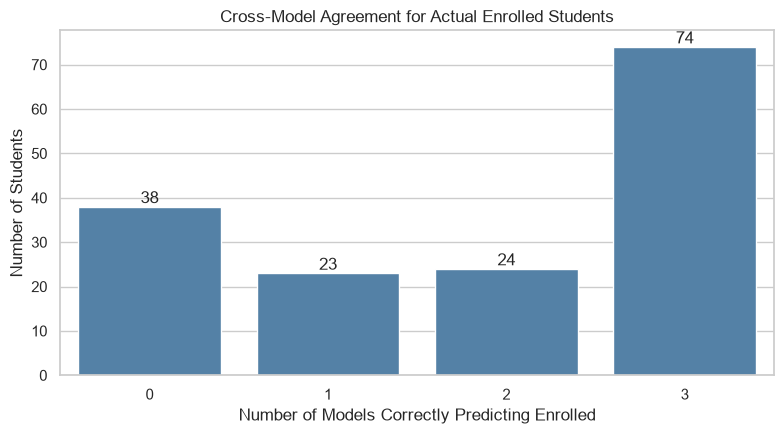

In [19]:
fig, ax = plt.subplots(figsize=(8, 4.5))

sns.barplot(
    data=summary,
    x="Number of models correct",
    y="Students",
    color="steelblue",
    ax=ax
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

ax.set_title(
    "Cross-Model Agreement for Actual Enrolled Students"
)
ax.set_xlabel(
    "Number of Models Correctly Predicting Enrolled"
)
ax.set_ylabel("Number of Students")

plt.tight_layout()
plt.show()


The cross-model agreement analysis shows that some Enrolled students are consistently difficult to identify across different classification methods. Among the 159 actual Enrolled students in the holdout set, 74 (46.5%) were correctly classified by all three models, while 38 (23.9%) were misclassified by all three.

Of these 38 consistently misclassified students, 15 were predicted as Dropout and 19 as Graduate by all three models. Therefore, most students missed by all three models were assigned the same incorrect outcome, rather than receiving different predictions across models.

These findings suggest that certain Enrolled students have observed characteristics that consistently resemble Dropout or Graduate profiles, even when different classification algorithms are used. Combined with the earlier academic-profile comparisons, this provides additional evidence that Enrolled overlaps with both terminal outcome groups rather than forming a clearly separated class.

## 9.11 Key Findings and Conclusion

The class-specific error analysis provides evidence that Enrolled is a difficult outcome to distinguish from both Dropout and Graduate. Across Logistic Regression, Random Forest, and XGBoost, actual Enrolled students are misclassified in both directions, with confusion toward Graduate occurring somewhat more frequently.

The subgroup comparisons reveal consistent differences in academic progress. Enrolled students predicted as Dropout generally have lower grades, fewer approved curricular units, and lower approval rates. In contrast, Enrolled students predicted as Graduate tend to have stronger academic performance, particularly in their approval rates and number of approved units. Correctly predicted Enrolled students generally fall between these groups. Financial indicators, including tuition payment status and debtor status, show similar differences.

Comparisons with actual Dropout and Graduate students further support this pattern. The Enrolled subgroups appear to occupy different positions along a continuum of academic progress rather than forming one clearly separated group.

Additional academic information improves Enrolled recall across all three models, but substantial misclassification remains even with Full Data. The probability analysis also indicates that some Enrolled students are assigned to other outcomes with relatively high model confidence.

The cross-model agreement analysis further supports this interpretation. Of the 159 actual Enrolled students, 38 (23.9%) were misclassified by all three models, and 34 of these students were consistently assigned the same incorrect outcome. Specifically, 15 students were classified as Dropout and 19 as Graduate by all three models. This suggests that some Enrolled students consistently resemble one of the two terminal outcome groups, rather than being misclassified only because of limitations of a particular algorithm.

Overall, these findings support the hypothesis that Enrolled is an intermediate or overlapping class whose students share characteristics with both Dropout and Graduate students. However, the analysis is descriptive and does not establish that academic or financial variables directly cause the prediction errors. The results suggest that the difficulty in predicting Enrolled is related not only to class imbalance or limited information, but also to substantial overlap in the observed characteristics of the three outcomes.

One limitation is that Enrolled represents a student's observed status rather than necessarily their final academic outcome. Some students labeled Enrolled may eventually graduate or drop out, making this class potentially more heterogeneous than the other two. In addition, these findings are based on a single holdout split, and the same students are evaluated across all three models. The results therefore provide descriptive evidence of overlapping academic profiles rather than proving that the overlap is the sole cause of misclassification. Finally, the Full Data analysis uses both semesters of academic information, so its results should not be interpreted as Day 1 prediction performance. Because all three models use the same holdout students and similar predictor information, agreement between models should not be interpreted as independent evidence.
